# Цена подержанных авто — предсказание (регрессия)

**Датасет:** Used Cars Dataset (Craigslist) — `austinreese/craigslist-carstrucks-data`

**Ноутбук 1 — EDA и предобработка**

Загружаем данные, исследуем, делаем предобработку и сохраняем очищенный датасет`vehicles_clean.csv` для ноутбука 2.

## 1. Импорты

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')
print('Библиотеки загружены')

Библиотеки загружены


## 2. Загрузка датасета с Kaggle


In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"annetslx","key":"ce9d7d70a532a189c228030bab97d591"}'}

In [ ]:
# Настройка Kaggle API
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!pip install -q kaggle

In [ ]:
# Скачиваем и распаковываем датасет
!kaggle datasets download -d austinreese/craigslist-carstrucks-data
!unzip -o craigslist-carstrucks-data.zip

Dataset URL: https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data
License(s): CC0-1.0
100% 262M/262M [00:03<00:00, 85.4MB/s]

Archive:  craigslist-carstrucks-data.zip
  inflating: vehicles.csv            


In [ ]:
df = pd.read_csv('vehicles.csv')
print('Размер таблицы (строки, столбцы):', df.shape)
df.head()

Размер таблицы (строки, столбцы): (426880, 26)


,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,image_url,description,county,state,lat,long,posting_date
0,7222695916,https://prescott.craigslist.org/cto/d/prescott...,prescott,https://prescott.craigslist.org,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az,NaN,NaN,NaN
1,7218891961,https://fayar.craigslist.org/ctd/d/bentonville...,fayetteville,https://fayar.craigslist.org,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar,NaN,NaN,NaN
2,7221797935,https://keys.craigslist.org/cto/d/summerland-k...,florida keys,https://keys.craigslist.org,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl,NaN,NaN,NaN
3,7222270760,https://worcester.craigslist.org/cto/d/west-br...,worcester / central MA,https://worcester.craigslist.org,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma,NaN,NaN,NaN
4,7210384030,https://greensboro.craigslist.org/cto/d/trinit...,greensboro,https://greensboro.craigslist.org,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc,NaN,NaN,NaN


## 3. Первичный осмотр

Смотрим типы данных, количество непустых значений и базовую статистику.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 26 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   url           426880 non-null  object 
 2   region        426880 non-null  object 
 3   region_url    426880 non-null  object 
 4   price         426880 non-null  int64  
 5   year          425675 non-null  float64
 6   manufacturer  409234 non-null  object 
 7   model         421603 non-null  object 
 8   condition     252776 non-null  object 
 9   cylinders     249202 non-null  object 
 10  fuel          423867 non-null  object 
 11  odometer      422480 non-null  float64
 12  title_status  418638 non-null  object 
 13  transmission  424324 non-null  object 
 14  VIN           265838 non-null  object 
 15  drive         296313 non-null  object 
 16  size          120519 non-null  object 
 17  type          334022 non-null  object 
 18  pain

In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,426880.0,NaN,NaN,NaN,7311486634.224333,4473170.412559,7207408119.0,7308143339.25,7312620821.0,7315253543.5,7317101084.0
url,426880,426880,https://wyoming.craigslist.org/ctd/d/atlanta-2...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,426880,404,columbus,3608,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region_url,426880,413,https://spokane.craigslist.org,2988,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,426880.0,NaN,NaN,NaN,75199.033187,12182282.173604,0.0,5900.0,13950.0,26485.75,3736928711.0
year,425675.0,NaN,NaN,NaN,2011.235191,9.45212,1900.0,2008.0,2013.0,2017.0,2022.0
manufacturer,409234,42,ford,70985,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,421603,29667,f-150,8009,NaN,NaN,NaN,NaN,NaN,NaN,NaN
condition,252776,6,good,121456,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cylinders,249202,8,6 cylinders,94169,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Пропуски

Считаем количество и процент пропусков по каждому столбцу — это поможет решить, что заполнять, а что удалять.

In [ ]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(1)
pd.DataFrame({'пропусков': missing, '%': missing_pct})

,пропусков,%
county,426880,100.0
size,306361,71.8
cylinders,177678,41.6
condition,174104,40.8
VIN,161042,37.7
drive,130567,30.6
paint_color,130203,30.5
type,92858,21.8
manufacturer,17646,4.1
title_status,8242,1.9


## 5. Целевая переменная — `price`

Цена сильно скошена и содержит мусор (минимум 0, гигантский максимум - отсюда решение фильтровать выбросы). Смотрим распределение и пробуем лог-преобразование.

count    4.268800e+05
mean     7.519903e+04
std      1.218228e+07
min      0.000000e+00
25%      5.900000e+03
50%      1.395000e+04
75%      2.648575e+04
max      3.736929e+09
Name: price, dtype: float64


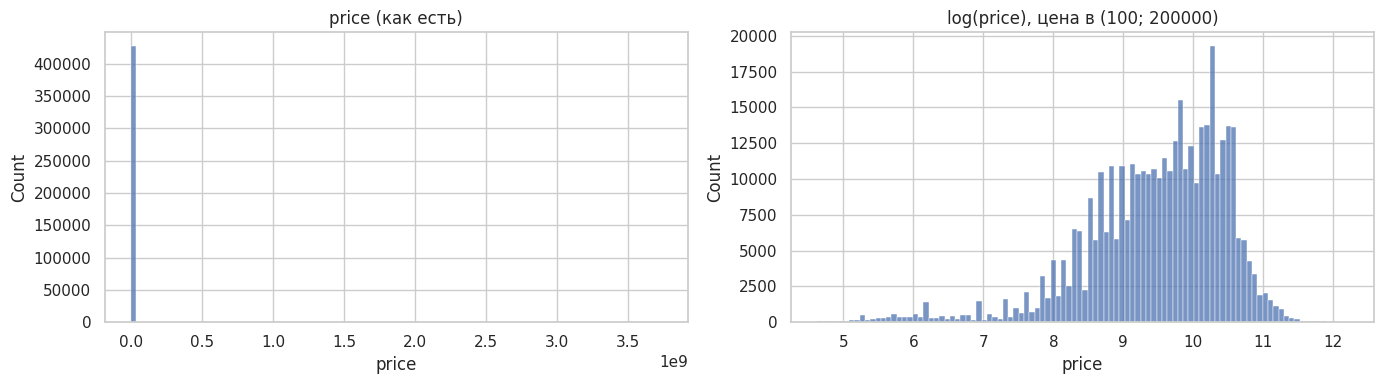

In [ ]:
print(df['price'].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['price'], bins=100, ax=axes[0])
axes[0].set_title('price (как есть)')

# Оставляем адекватный диапазон цены и берём логарифм
valid = df[(df['price'] > 100) & (df['price'] < 200000)]
sns.histplot(np.log1p(valid['price']), bins=100, ax=axes[1])
axes[1].set_title('log(price), цена в (100; 200000)')
plt.tight_layout()
plt.show()

## 6. Предобработка данных

Убираем неинформативные столбцы, чистим выбросы и пропуски, добавляем производные признаки. На каждом шаге печатаем размер таблицы, чтобы контролировать потери данных.

### 6.1 Удаление неинформативных столбцов

Удаляем то, что не несёт сигнала о цене или дублирует информацию:
- `id, url, region_url, image_url` — технические идентификаторы и ссылки;
- `VIN` — уникален почти для каждой машины, для модели бесполезен;
- `description` — свободный текст (отдельная NLP-задача, вне скоупа);
- `county` — пустой на 100 %;
- `lat, long, posting_date` — координаты/время объявления, а не цена авто (география уже есть в `state`/`region`).

In [ ]:
drop_cols = ['id', 'url', 'region_url', 'VIN', 'image_url',
             'description', 'county', 'lat', 'long', 'posting_date']
df = df.drop(columns=drop_cols)
print('Столбцов осталось:', df.shape[1])
df.columns.tolist()

Столбцов осталось: 16


['region',
 'price',
 'year',
 'manufacturer',
 'model',
 'condition',
 'cylinders',
 'fuel',
 'odometer',
 'title_status',
 'transmission',
 'drive',
 'size',
 'type',
 'paint_color',
 'state']

### 6.2 Фильтрация выбросов и нереалистичных значений

В `describe()` виден мусор: `price` доходит до 3.7 млрд, `odometer` — до 10 млн миль, `year` — с 1900. Оставляем разумные диапазоны:
- `price` в (100; 200 000) — отсекаем фейковые 0–1 \$ и опечатки-миллиарды;
- `year` в [1990; 2022] — современный рынок;
- `odometer` в (0; 400 000) — реальный пробег.

In [ ]:
before = len(df)
df = df[(df['price'] > 100) & (df['price'] < 200000)]
df = df[(df['year'] >= 1990) & (df['year'] <= 2022)]
df = df[(df['odometer'] > 0) & (df['odometer'] < 400000)]
removed = before - len(df)
print(f'Удалено строк: {removed} ({removed / before * 100:.1f}%)')
print('Осталось строк:', len(df))

Удалено строк: 53803 (12.6%)
Осталось строк: 373077


### 6.3 Обработка пропусков

Две стратегии:
- **Удаляем строки**, где пуст ключевой признак, без которого объявление бессмысленно: `manufacturer, model, fuel, transmission, odometer, year`.
- **Заполняем `'unknown'`** категориальные признаки с большой долей пропусков (`condition, cylinders, drive, type, paint_color, title_status, size`) — сам факт пропуска информативен, а удалять 30–70 % строк нельзя.

In [ ]:
df = df.dropna(subset=['manufacturer', 'model', 'fuel', 'transmission', 'odometer', 'year'])
for col in ['condition', 'cylinders', 'drive', 'type', 'paint_color', 'title_status', 'size']:
    df[col] = df[col].fillna('unknown')
print('Осталось строк:', len(df))
print('Пропусков в таблице:', int(df.isna().sum().sum()))

Осталось строк: 354487
Пропусков в таблице: 0


### 6.4 Производные признаки

Добавляем два полезных признака:
- `age` — возраст авто (год среза данных 2022 минус `year`); линейным моделям он понятнее самого года;
- `log_price` — логарифм цены: целевая переменная в виде, близком к нормальному (см. раздел 5).

In [ ]:
df['age'] = 2022 - df['year']
df['log_price'] = np.log1p(df['price'])
df[['year', 'age', 'price', 'log_price']].head()

,year,age,price,log_price
27,2014.0,8.0,33590,10.422013
28,2010.0,12.0,22590,10.025307
29,2020.0,2.0,39590,10.586357
30,2017.0,5.0,30990,10.341452
31,2013.0,9.0,15000,9.615872


**Вывод по пункту 6.** После предобработки: **26 -> 16** значимых столбцов, **426 880 -> 354 487** строк (потеряли ≈ 17 % из-за мусора и пропусков), пропусков **0**, добавлены 2 производных признака. Датасет готов к анализу и моделированию.

## 7. Углублённый EDA — связи признаков с ценой

Смотрим, как цена зависит от числовых (`year`, `odometer`) и категориальных (`transmission`, `fuel`, `type`, `manufacturer`) признаков.

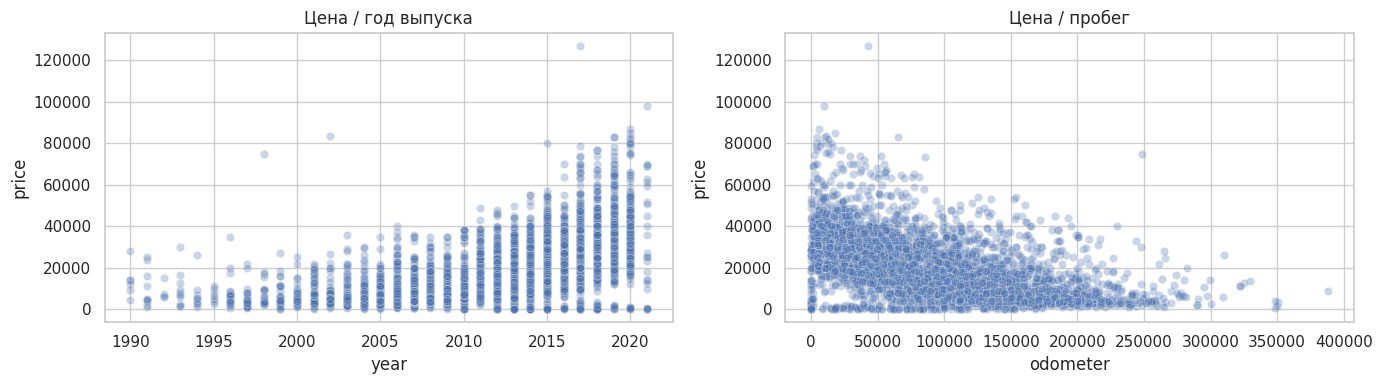

In [ ]:
sample = df.sample(5000, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.scatterplot(data=sample, x='year', y='price', alpha=0.3, ax=axes[0])
axes[0].set_title('Цена / год выпуска')
sns.scatterplot(data=sample, x='odometer', y='price', alpha=0.3, ax=axes[1])
axes[1].set_title('Цена / пробег')
plt.tight_layout()
plt.show()

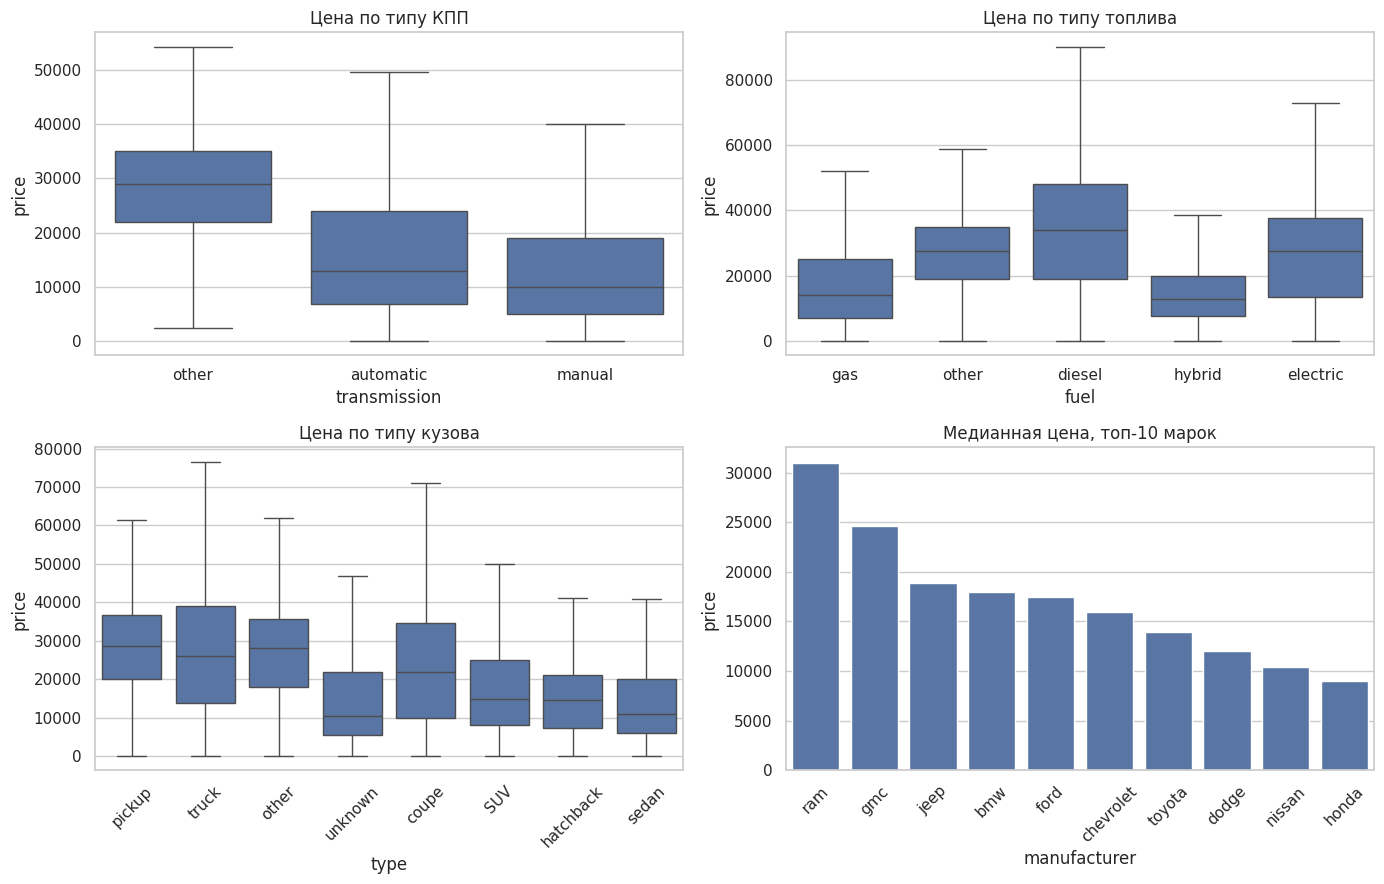

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.boxplot(data=df, x='transmission', y='price', showfliers=False, ax=axes[0, 0])
axes[0, 0].set_title('Цена по типу КПП')
sns.boxplot(data=df, x='fuel', y='price', showfliers=False, ax=axes[0, 1])
axes[0, 1].set_title('Цена по типу топлива')

top_types = df['type'].value_counts().head(8).index
sns.boxplot(data=df[df['type'].isin(top_types)], x='type', y='price', showfliers=False, ax=axes[1, 0])
axes[1, 0].set_title('Цена по типу кузова')
axes[1, 0].tick_params(axis='x', rotation=45)

top_man = df['manufacturer'].value_counts().head(10).index
order = (df[df['manufacturer'].isin(top_man)].groupby('manufacturer')['price']
         .median().sort_values(ascending=False).index)
sns.barplot(data=df[df['manufacturer'].isin(top_man)], x='manufacturer', y='price',
            estimator=np.median, errorbar=None, order=order, ax=axes[1, 1])
axes[1, 1].set_title('Медианная цена, топ-10 марок')
axes[1, 1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

**Выводы по EDA:**
- **Год / цена:** связь положительная — чем новее авто, тем дороже (корреляция ≈ **+0.57**).
- **Пробег / цена:** связь отрицательная — больше пробег, ниже цена (≈ **−0.54**).
- **КПП:** медиана `automatic` ≈ 12 995 \$ против `manual` ≈ 9 990 \$ (`other` — спорт/спецтехника, завышает медиану).
- **Топливо:** дороже всего `diesel` (≈ 33 990 \$) и `electric` (≈ 27 400 \$), дешевле `gas` (≈ 13 990 \$).
- **Кузов:** `pickup`/`truck` (≈ 26–29 тыс.) заметно дороже `sedan` (≈ 11 тыс.).
- **Марки:** дороже всего `ram` (≈ 31 тыс.), `gmc`, `jeep`; дешевле массовые `honda`, `nissan` (9–10 тыс.).

## 8. Корреляционная матрица числовых признаков

Проверяем взаимосвязи числовых признаков и мультиколлинеарность.

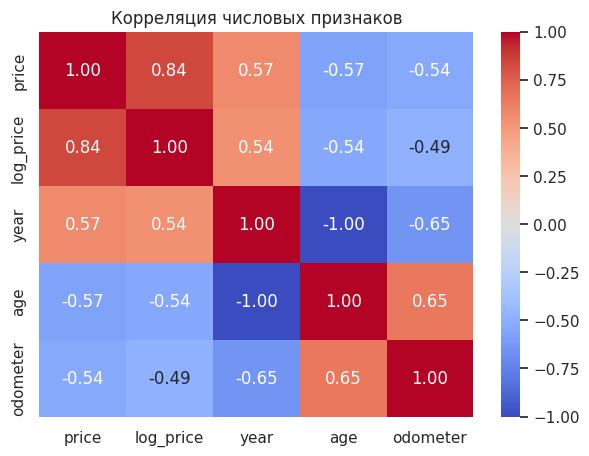

In [ ]:
num_cols = ['price', 'log_price', 'year', 'age', 'odometer']
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляция числовых признаков')
plt.show()

**Вывод.** `year` и `age` — один и тот же сигнал с обратным знаком (корреляция ≈ −1.0), модели достаточно **одного** из них. С ценой сильнее всего связаны `year`/`age` (≈ ±0.57) и `odometer` (≈ −0.54). Сильной мультиколлинеарности между независимыми предикторами (`odometer` и `year`) нет.

## 9. Сохранение очищенного датасета

Сохраняем `vehicles_clean.csv`: целевая `price` плюс набор информативных признаков. Кодирование (One-Hot) и масштабирование Участник 2 делает **внутри pipeline** — так нет утечки данных при кросс-валидации, поэтому здесь категории оставляем строками.

In [ ]:
clean_cols = ['price', 'year', 'odometer',
              'manufacturer', 'condition', 'cylinders', 'fuel', 'title_status',
              'transmission', 'drive', 'size', 'type', 'paint_color']
df_clean = df[clean_cols]
df_clean.to_csv('vehicles_clean.csv', index=False)
print('Сохранено: vehicles_clean.csv', df_clean.shape)
print('Колонки:', list(df_clean.columns))

## Итог: что выполнено

- Загрузка и первичный осмотр (`shape`, `info`, `describe`).
- Анализ пропусков по всем 26 столбцам.
- Анализ целевой `price` + обоснование `log(price)`.
- Предобработка: удаление неинформативных столбцов, фильтрация выбросов, обработка пропусков, производные признаки (`age`, `log_price`) для анализа.
- Углублённый EDA: связи цены с `year`, `odometer`, `transmission`, `fuel`, `type`, `manufacturer` + корреляционная матрица.
- Сохранение очищенного датасета `vehicles_clean.csv` для Участника 2.

